In [25]:
import lsdb
import nested_pandas as npd
import torch
import numpy as np

print(npd.__version__, lsdb.__version__)

0.7.3.dev23+ga57123467 0.11.1


# Milestone 2: HATS Single Image Cutouts and Spectra

Definition: A working prototype of a HATS catalog storing single image cutouts and spectra for each object.

Quantitative Metrics: Multi-modal data set for at least 100,000 objects is available on the American Science Cloud.

## Accessing the Milestone 2 Catalog

The catalog created for Milestone 2 combines image cutouts from legacy Survey South with Spectra from DESI. This combination is done via an LSDB crossmatch, with a notebook that reproduces the creation of the catalog available in this directory (generate_m2_dataset.ipynb)

In [12]:
m2_cat = lsdb.open_catalog("/sdf/data/rubin/cosmicdata/lsdb/genesis/milestone2")
m2_cat

,ra_mmu_legacysurvey_dr10_south_21,dec_mmu_legacysurvey_dr10_south_21,spectrum,ra_mmu_desi_edr_sv3,dec_mmu_desi_edr_sv3,_dist_arcsec,image_flux_g,image_mask_g,image_ivar_g,image_psf_fwhm_g,image_scale_g,image_flux_r,image_mask_r,image_ivar_r,image_psf_fwhm_r,image_scale_r
npartitions=548,,,,,,,,,,,,,,,,
"Order: 7, Pixel: 41472",double[pyarrow],double[pyarrow],"nested<flux: [float], ivar: [float], lsf_sigma...",double[pyarrow],double[pyarrow],double[pyarrow],"tensor[float, (160, 160)]","tensor[bool, (160, 160)]","tensor[float, (160, 160)]",float[pyarrow],float[pyarrow],"tensor[float, (160, 160)]","tensor[bool, (160, 160)]","tensor[float, (160, 160)]",float[pyarrow],float[pyarrow]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112605",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"Order: 7, Pixel: 112607",...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...


(<Figure size 1000x500 with 2 Axes>,
 <WCSAxes: title={'center': 'Catalog pixel map - mmu_legacysurvey_dr10_south_21_x_mmu_desi_edr_sv3'}>)

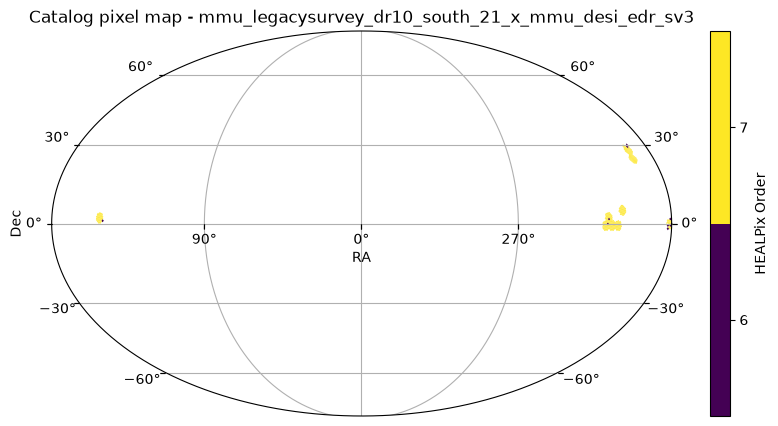

In [14]:
# On-sky distribution of objects in catalog
m2_cat.plot_pixels()

## Basic Catalog Inspection

In [8]:
# Number of objects in catalog, which should exceed 100,000
print(f"This catalog has {len(m2_cat)} objects available")

This catalog has 172580 objects available


Building task graph...


Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

ra_mmu_legacysurvey_dr10_south_21  \
_healpix_29                                             
729594401347125473                         196.606908   
729594698490995941                         196.570395   
729594759487585526                         196.598615   
729594842788931257                         196.556864   
729594847830835346                         196.551128   

                    dec_mmu_legacysurvey_dr10_south_21  ra_mmu_desi_edr_sv3  \
_healpix_29                                                                   
729594401347125473                           24.939503            196.60691   
729594698490995941                            24.92532            196.57039   
729594759487585526                           24.943988           196.598614   
729594842788931257                            24.95042           196.556863   
729594847830835346                           24.949316           196.551126   

                    dec_mmu_desi_edr_sv3  _dist_arcsec       image_flux_g  \
_healpix_29                                                                 
729594401347125473             24.939503      0.009472  [160×160] float32   
729594698490995941             24.925322      0.016867  [160×160] float32   
729594759487585526             24.943988      0.001531  [160×160] float32   
729594842788931257             24.950424      0.017383  [160×160] float32   
729594847830835346             24.949317      0.009984  [160×160] float32   

                      image_mask_g       image_ivar_g  image_psf_fwhm_g  \
_healpix_29                                                               
729594401347125473  [160×160] bool  [160×160] float32          1.659991   
729594698490995941  [160×160] bool  [160×160] float32          1.659991   
729594759487585526  [160×160] bool  [160×160] float32          1.659991   
729594842788931257  [160×160] bool  [160×160] float32          1.584679   
729594847830835346  [160×160] bool  [160×160] float32          1.584679   

                    image_scale_g       image_flux_r    image_mask_r  \
_healpix_29                                                            
729594401347125473          0.262  [160×160] float32  [160×160] bool   
729594698490995941          0.262  [160×160] float32  [160×160] bool   
729594759487585526          0.262  [160×160] float32  [160×160] bool   
729594842788931257          0.262  [160×160] float32  [160×160] bool   
729594847830835346          0.262  [160×160] float32  [160×160] bool   

                         image_ivar_r  image_psf_fwhm_r  image_scale_r  \
_healpix_29                                                              
729594401347125473  [160×160] float32          1.409774          0.262   
729594698490995941  [160×160] float32          1.606712          0.262   
729594759487585526  [160×160] float32          1.606712          0.262   
729594842788931257  [160×160] float32          1.477628          0.262   
729594847830835346  [160×160] float32          1.419423          0.262   

                                                             spectrum  
_healpix_29                                                            
729594401347125473  [{flux: 5.987331, ivar: 0.153955, lsf_sigma: 0...  
729594698490995941  [{flux: -1.951323, ivar: 0.044572, lsf_sigma: ...  
729594759487585526  [{flux: 3.759151, ivar: 0.04319, lsf_sigma: 0....  
729594842788931257  [{flux: -0.543011, ivar: 0.046027, lsf_sigma: ...  
729594847830835346  [{flux: 18.797222, ivar: 0.016184, lsf_sigma: ...
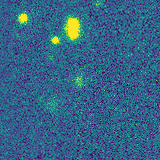
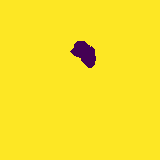
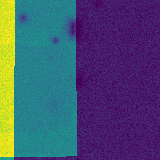
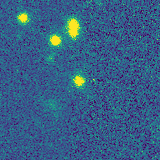
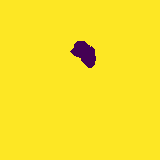
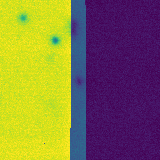
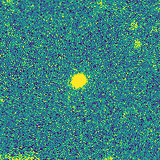
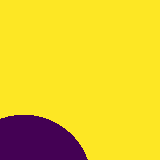
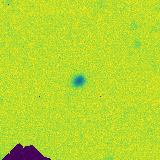
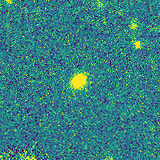
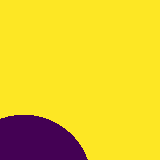
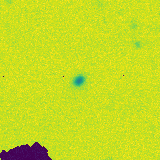
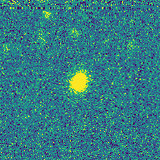
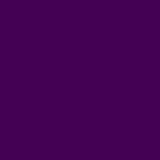
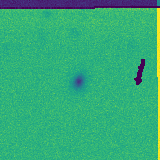
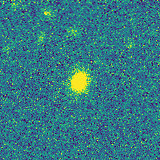
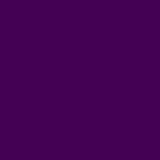
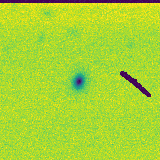
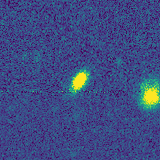
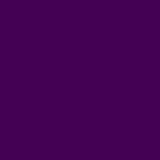
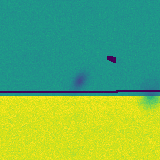
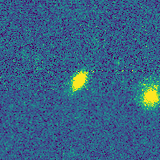
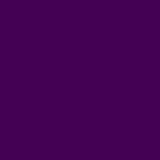
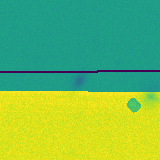
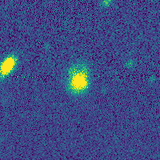
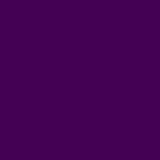
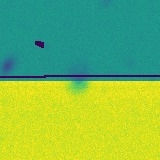
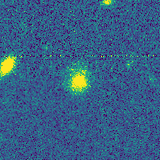
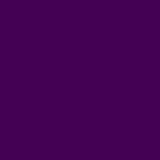
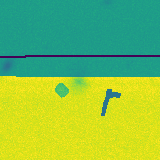

In [15]:
# Bring a few objects into memory
m2_nf = m2_cat.head(5)
m2_nf

,image_flux_g,image_mask_g,image_ivar_g,image_flux_r,image_mask_r,image_ivar_r
729594401347125473,0.0145-0.00643,10,1.5e+057.83e+04,0.0317-0.0129,10,4.13e+041.97e+04
729594698490995941,0.00912-0.0072,10,8.87e+043.6e+04,0.0195-0.0144,10,2.17e+048.25e+03
729594759487585526,0.0104-0.00718,21,1.08e+053.91e+04,0.0214-0.0142,21,2.19e+041.21e+04
729594842788931257,0.0258-0.00706,21,1.13e+052.48e+04,0.0345-0.0147,21,2.71e+045.42e+03
729594847830835346,0.0258-0.00683,21,1.14e+052.49e+04,0.0351-0.0143,21,2.71e+045.42e+03

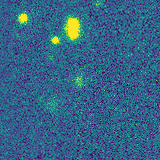
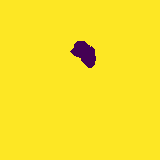
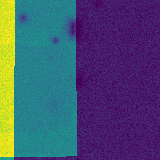
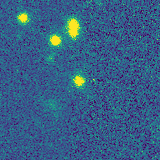
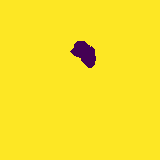
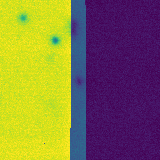
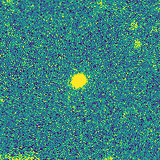
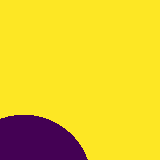
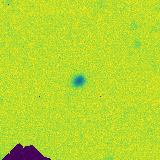
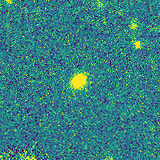
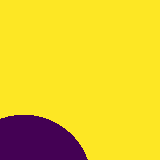
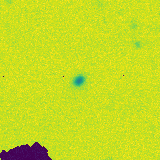
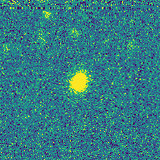
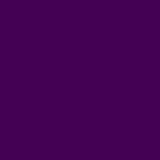
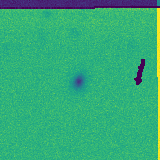
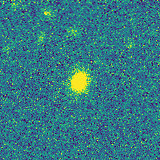
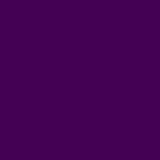
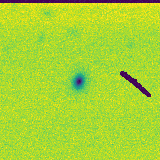
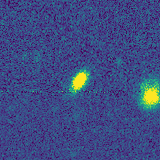
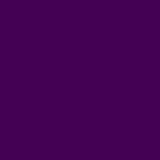
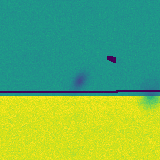
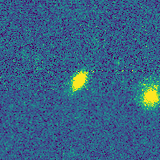
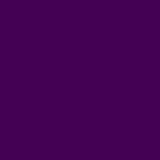
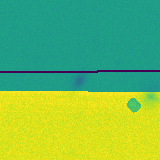
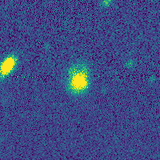
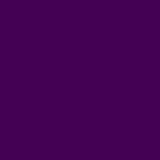
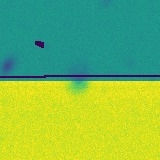
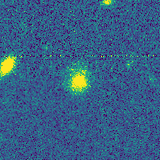
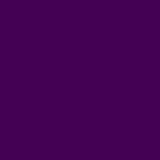
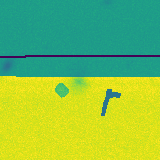

In [16]:
# The catalog has cutouts for two photometric bands (g,r) available
m2_nf[["image_flux_g","image_mask_g","image_ivar_g","image_flux_r","image_mask_r","image_ivar_r"]]

In [17]:
# And has a spectrum available as a nested column
m2_nf[["spectrum"]]

spectrum
_healpix_29                                                          
729594401347125473  [{flux: 5.987331, ivar: 0.153955, lsf_sigma: 0...
729594698490995941  [{flux: -1.951323, ivar: 0.044572, lsf_sigma: ...
729594759487585526  [{flux: 3.759151, ivar: 0.04319, lsf_sigma: 0....
729594842788931257  [{flux: -0.543011, ivar: 0.046027, lsf_sigma: ...
729594847830835346  [{flux: 18.797222, ivar: 0.016184, lsf_sigma: ...

## Creating Pytorch Tensors from LSDB Images and Spectra

In [47]:
# Create a torch tensor from an image cutout
image_arr = np.stack(m2_nf["image_flux_g"].to_numpy())
image_tensor = torch.from_numpy(flux_arr)
image_tensor[0] # show the tensor for 1 object

tensor([[-2.1277e-03, -8.7358e-04, -1.3708e-03,  ..., -1.6368e-03,
          8.3657e-04,  2.4782e-03],
        [-2.3966e-03, -8.5482e-04,  1.7264e-03,  ...,  6.9853e-04,
          4.5900e-03,  2.8863e-03],
        [ 4.3035e-03,  5.4703e-03,  3.3364e-03,  ..., -2.4181e-03,
          2.0973e-05, -3.2264e-03],
        ...,
        [ 2.8813e-03,  2.7812e-03, -5.2871e-04,  ..., -2.9186e-03,
          2.1075e-03, -2.4806e-03],
        [-2.8167e-03, -1.3831e-03, -1.4333e-03,  ..., -6.6009e-03,
         -3.0546e-03,  4.5980e-04],
        [ 9.9327e-04,  1.2030e-03, -2.2335e-03,  ..., -1.5085e-03,
         -5.4271e-05, -4.0459e-03]])

In [48]:
# Create a torch tensor from a spectrum (just "flux" column)
spec_arr = np.stack(m2_nf["spectrum"].nest.to_lists()["flux"].to_numpy())
spec_tensor = torch.from_numpy(spec_arr)
spec_tensor

tensor([[ 5.9873e+00, -7.6158e+00, -9.9156e-01,  ...,  1.7003e+00,
          1.4852e+00,  9.9474e-01],
        [-1.9513e+00, -5.5084e+00,  1.6645e+00,  ...,  2.1859e+00,
          1.5653e+00,  2.3917e+00],
        [ 3.7592e+00,  4.4761e+00,  4.3572e+00,  ...,  2.7478e+00,
          3.3082e+00,  3.1002e+00],
        [-5.4301e-01, -1.1260e+00, -8.7583e-01,  ...,  9.1493e-01,
          1.7391e+00,  1.2109e+00],
        [ 1.8797e+01, -3.4555e-01, -6.6799e+00,  ..., -2.3139e-01,
          4.3585e-01,  1.1911e-02]])